# Лабораторная работа №3: Алгоритмы последовательного выбора признаков
__Цель работы:__
1. Обучить базовую модель kNN.
2. Реализовать алгоритм последовательного обратного выбора (SBS).

#### __1. Загрузка данных и подготовка__

Загрузим подготовленный датасет из 2 лабораторной работы.

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

# Настройка отображения
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Загрузка данных
df = pd.read_csv('Data\Dataset_2laba.csv', sep = ',', encoding='latin1')
print("Размер данных:", df.shape)
print("\nПервые 5 строк:")
df.head()

Размер данных: (498, 9)

Первые 5 строк:


,duration,instance_index,avg_cpus,avg_memory,max_cpus,max_memory,page_cache_memory,cycles_per_instruction_norm,memory_accesses_per_instruction_std
0,0.3,111,0.008392,0.009476,0.047913,0.019379,0.003220,0.063542,-0.788944
1,0.3,111,0.027100,0.027618,0.073608,0.027954,0.001808,0.063542,-0.788944
2,0.3,111,0.024933,0.012466,0.117676,0.019287,0.002392,0.087088,-0.245127
3,0.3,111,0.019135,0.010956,0.120972,0.019318,0.001934,0.095564,-0.217250
4,0.3,111,0.001163,0.000959,0.011063,0.001957,0.000813,0.063542,-0.788944


#### __2.Создание латентного признака__

In [21]:
# Латентный признак 1: Соотношение максимальной к средней памяти (вариативность использования памяти)
df['memory_variability'] = df['max_memory'] / (df['avg_memory'] + 1e-8)

# Латентный признак 2: Соотношение максимальной к средней CPU (вариативность использования cpu)
df['cpu_variability'] = df['max_cpus'] / (df['avg_cpus'] + 1e-8)

# Латентый признак 1: среднее использование памяти
#df['memory_variability'] = (df['avg_memory'] + df['max_memory']) / 2

# Латентый признак 2: среднее использование CPU
#df['cpu_variability'] = (df['avg_cpus'] + df['max_cpus']) / 2

#### __3.Анализ целевой переменной__


In [27]:
# Создаем целевую переменную - преобразуем instance_index в категории
# Так как значений много (47 уникальных), сгруппируем их в 3 класса:
# - Класс 0: малочисленные индексы (редкие задачи)
# - Класс 1: среднечисленные индексы (что-то между)
# - Класс 2: многочисленные индексы (частые задачи)

# Получаем частоты каждого индекса
freq = df['instance_index'].value_counts()

# Создаем целевую переменную
threshold_low = freq.quantile(0.33)
threshold_high = freq.quantile(0.67)

def classify_index(idx):
    count = freq[idx]
    if count <= threshold_low:
        return 0  # Редкие задачи
    elif count <= threshold_high:
        return 1  # Средние по частоте
    else:
        return 2  # Частые задачи

df['target'] = df['instance_index'].apply(classify_index)

# Удаляем instance_index из признаков (теперь это целевая переменная)
features = ['duration', 'cpu_variability', 'memory_variability', 'max_cpus', 
            'max_memory', 'page_cache_memory', 'cycles_per_instruction_norm', 'memory_accesses_per_instruction_std']
X = df[features].copy()
y = df['target'].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
#X_scaled = pd.DataFrame(X_scaled, columns=features)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42)

print(f"Используемые признаки: {len(features)}")
print(features)

Используемые признаки: 8
['duration', 'cpu_variability', 'memory_variability', 'max_cpus', 'max_memory', 'page_cache_memory', 'cycles_per_instruction_norm', 'memory_accesses_per_instruction_std']


#### __4.Обучение базовой модели kNN__

In [28]:
scaler = StandardScaler()

X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_std, y_train)

y_pred_all = knn.predict(X_test_std)
accuracy_all = accuracy_score(y_test, y_pred_all)

descriptions = {
    'duration':                             'Длительность задачи (сек)',
    'cpu_variability':                      'вариативность использования памяти (рассчитанный)',
    'memory_variability':                   'вариативность использования cpu (рассчитанный)',
    'max_cpus':                             'Максимальное использование CPU',
    'max_memory':                           'Максимальное использование памяти',
    'page_cache_memory':                    'Страничный кэш памяти',
    'cycles_per_instruction_norm':          'Тактов на инструкцию',
    'memory_accesses_per_instruction_std':  'Обращений к памяти на инструкцию'
}
print(f"KNN на {len(features)} признаках")
for i, feature in enumerate(features, 1):
    desc = descriptions.get(feature, "Дополнительный параметр")
    print(f"{i:2}. {feature:35} | {desc}")
print(f"ИТОГОВАЯ ТОЧНОСТЬ: {accuracy_all:.2%}")

KNN на 8 признаках
 1. duration                            | Длительность задачи (сек)
 2. cpu_variability                     | вариативность использования памяти (рассчитанный)
 3. memory_variability                  | вариативность использования cpu (рассчитанный)
 4. max_cpus                            | Максимальное использование CPU
 5. max_memory                          | Максимальное использование памяти
 6. page_cache_memory                   | Страничный кэш памяти
 7. cycles_per_instruction_norm         | Тактов на инструкцию
 8. memory_accesses_per_instruction_std | Обращений к памяти на инструкцию
ИТОГОВАЯ ТОЧНОСТЬ: 73.33%


#### __5.Реализация алгоритма последовательного обратного выбора (SBS)__

In [30]:
def sbs_algorithm_detailed(X_train, X_test, y_train, y_test, model, feature_names):
    #  набор индексов признаков
    current_features = list(range(X_train.shape[1]))
    history = []

    # оценк точности на полном наборе данных
    model.fit(X_train, y_train)
    initial_score = accuracy_score(y_test, model.predict(X_test))
    history.append((len(current_features), initial_score, "None", tuple(current_features)))
    print(f"{'Осталось':<10} | {'Удален признак':<35} | {'Accuracy':<10}")
    print(f"{len(current_features):<10} | {'---':<35} | {initial_score:.4f}")

    while len(current_features) > 1:
        best_score = -1
        feature_to_remove_idx = -1
        for f in current_features:
            subset = [idx for idx in current_features if idx != f]
            # обучаем модель
            model.fit(X_train[:, subset], y_train)
            score = accuracy_score(y_test, model.predict(X_test[:, subset]))
            if score >= best_score:
                best_score = score
                feature_to_remove_idx = f
        removed_name = feature_names[feature_to_remove_idx]
        current_features.remove(feature_to_remove_idx)
        history.append((len(current_features), best_score, removed_name, tuple(current_features)))
        print(f"{len(current_features):<10} | {removed_name:<35} | {best_score:.4f}")
    return history

knn_optimized = KNeighborsClassifier(n_neighbors=5)

scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

sbs_history = sbs_algorithm_detailed(X_train_std, X_test_std, y_train, y_test, knn_optimized, features)

Осталось   | Удален признак                      | Accuracy  
8          | ---                                 | 0.7333
7          | memory_accesses_per_instruction_std | 0.7867
6          | memory_variability                  | 0.7933
5          | duration                            | 0.8267
4          | max_cpus                            | 0.7800
3          | cpu_variability                     | 0.7600
2          | page_cache_memory                   | 0.7600
1          | cycles_per_instruction_norm         | 0.7133


#### __6.Визуализация зависимости точности от количества признаков__

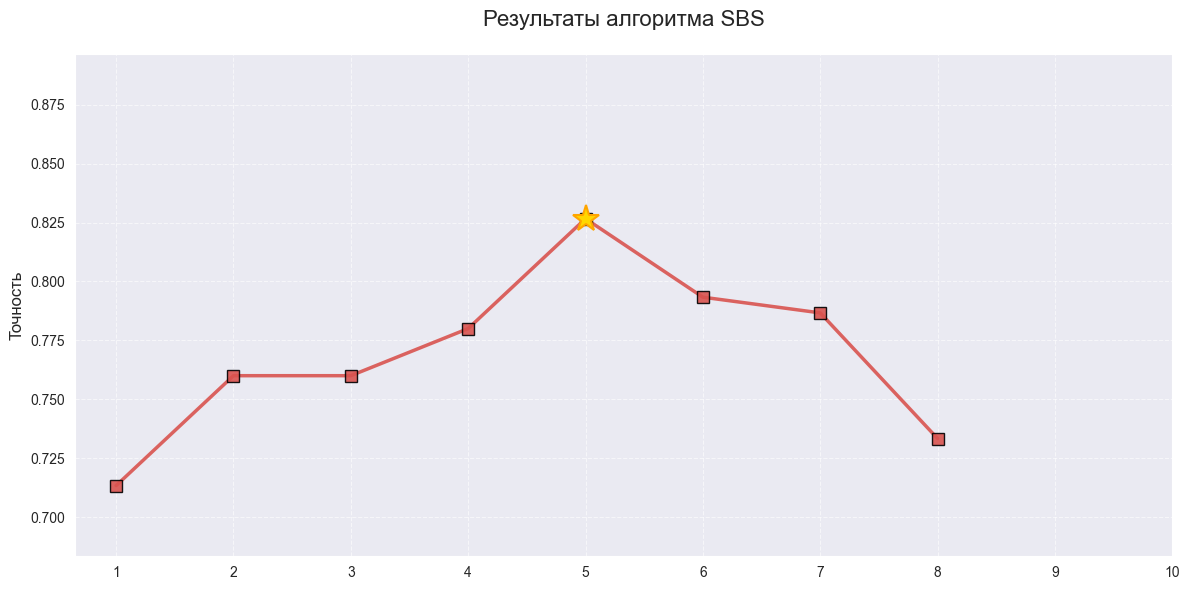

Результаты SBS:
- Исходная точность (8 признаков):  0.7333
- Максимальная точность:            0.8267 (при 5 признаках)
- Прирост за счет отбора:           0.0933


In [33]:
# подготовка данных из списка sbs_history
# sbs_history содержит (кол-во, точность, имя_удаленного, индексы)
sbs_raw_x = np.array([item[0] for item in sbs_history], dtype=int)
sbs_raw_y = np.array([item[1] for item in sbs_history], dtype=float)


sort_idx = np.argsort(sbs_raw_x)
sbs_x = sbs_raw_x[sort_idx]
sbs_y = sbs_raw_y[sort_idx]

max_acc = np.max(sbs_y)
best_n = sbs_x[np.argmax(sbs_y)]

plt.figure(figsize=(12, 6))

# график SBS
plt.plot(sbs_x, sbs_y, marker='s', label='SBS (Обратное исключение)', color='#d9534f', linewidth=2.5, markersize=9, linestyle='-', markeredgecolor='black', alpha=0.9)
plt.plot(best_n, max_acc, '*', color='gold', markersize=20, markeredgecolor='orange', markeredgewidth=1.5, zorder=5)
plt.title('Результаты алгоритма SBS', fontsize=16, pad=20)
plt.ylabel('Точность', fontsize=12)

# Сетка и оси
plt.xticks(range(1, 11))
plt.ylim(sbs_y.min() - 0.03, sbs_y.max() + 0.07)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print(f"Результаты SBS:")
print(f"- Исходная точность (8 признаков):  {sbs_y[-1]:.4f}")
print(f"- Максимальная точность:            {max_acc:.4f} (при {best_n} признаках)")
print(f"- Прирост за счет отбора:           {max_acc - sbs_y[-1]:.4f}")

In [26]:
new_columns = [
    'duration',                             #'Длительность задачи (сек)',
    'instance_index',                       # Индекс задачи в коллекции
    'memory_variability',                   #'вариативность использования cpu (рассчитанный)',
    'avg_cpus',                             #'Среднее использование CPU',
    'avg_memory',                           #'Среднее использование памяти',
    'max_cpus',                             #'Максимальное использование CPU',
    'max_memory',                           #'Максимальное использование памяти',
    'page_cache_memory',                    #'Страничный кэш памяти',
    'cycles_per_instruction_norm',          #'Тактов на инструкцию',
    'memory_accesses_per_instruction_std',  #'Обращений к памяти на инструкцию'
]

df_cleaned = df[new_columns].copy()

# Сохраняем
df_cleaned.to_csv("Data/Dataset_3laba.csv", index=False)
print(f"Создан новый датасет: Data/Dataset_3laba.csv")
print(f"Размер нового файла: {df_cleaned.shape[0]} строк и {df_cleaned.shape[1]} колонок")

Создан новый датасет: Data/Dataset_3laba.csv
Размер нового файла: 498 строк и 10 колонок
